# Pronóstico del valor del suelo

¿Cuánto costará el m² de terreno en los próximos años, y en qué manzanas subirá
más que en el resto de la ciudad?

El insumo es el valor de referencia de Catastro 2017-2026: diez años para unas
40 mil manzanas. Diez puntos por serie son pocos para series de tiempo, y 40 mil
series en paralelo son muchas para un modelo transversal. Por eso el crecimiento
de cada manzana se parte en dos:

| | Qué es | Datos | Cómo se ataca |
|---|---|---|---|
| **Deriva** | lo que sube la ciudad entera | **una** serie de 10 puntos | series de tiempo (Parte A) |
| **Relativo** | lo que cada manzana le gana o le pierde a la ciudad | 40 mil filas | aprendizaje supervisado (Parte B) |

La Parte C los vuelve a juntar.

> `V_REF` no es un precio de transacción: es un valor administrativo que
> Catastro actualiza por zonas y por turnos. Deja huellas —un año congelado,
> crecimientos que se alternan— que hay que tener presentes antes de creerle a
> cualquier pronóstico.

In [1]:
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNetCV, LinearRegression, RidgeCV
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")      # statsmodels avisa de convergencia con series tan cortas
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config as C

H = 3                     # horizonte de cada ejercicio, en años
ORIGEN_TRAIN = 2020       # se entrena prediciendo 2020 -> 2023
ORIGEN_TEST = 2023        # se evalua prediciendo 2023 -> 2026
ANIOS_PRONOSTICO = 4      # 2027 ... 2030
K_VECINOS = 8
N_BOOT = 300              # remuestreos por sector

AZUL, VERDE, NARANJA, ROJO, GRIS = "#264653", "#2a9d8f", "#f4a261", "#e76f51", "#9aa5ab"
TAM_MAPA = (5, 8)
rng = np.random.default_rng(C.SEMILLA)

def pesos(x, pos=None):
    return "%.1f M" % (x / 1e6) if x >= 1e6 else "%.0f k" % (x / 1e3)

pct = lambda g: 100 * (10 ** g - 1)        # crecimiento anual en log10 -> % anual

## 1. El panel: una fila por manzana, una columna por año

Se trabaja en **logaritmo base 10**: el precio va de miles a decenas de millones
y lo que interesa son cambios porcentuales, que en logaritmo son restas.

In [2]:
serie = pd.read_csv(C.SERIE, dtype={"MANCODIGO": str})
n_cero = int((serie["V_REF"] <= 0).sum())
# un 0 no es un precio; y hay manzanas repetidas dentro de un año: se toma la mediana
serie = serie[serie["V_REF"] > 0].groupby(["MANCODIGO", "ANO"], as_index=False)["V_REF"].median()

ancha = serie.pivot(index="MANCODIGO", columns="ANO", values="V_REF")
completas = ancha.dropna()
LOG = np.log10(completas)

print("registros con precio: %d (descartados %d en cero)" % (len(serie), n_cero))
print("manzanas en la capa : %d | con los diez años: %d (%.0f %%)"
      % (len(ancha), len(completas), 100 * len(completas) / len(ancha)))

registros con precio: 421896 (descartados 1111 en cero)
manzanas en la capa : 43692 | con los diez años: 40610 (93 %)


años congelados (mas del 80% de manzanas sin cambio): [2022]
razon p90/p10: 6.1 en 2017 -> 5.1 en 2026


ANO,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mediana_ciudad,1200000.0,1400000.0,1550000.0,1800000.0,1950000.0,1950000.0,2100000.0,2210000.0,2400000.0,2650000.0
crecimiento_pct,NaN,16.7,10.7,16.1,8.3,0.0,7.7,5.2,8.6,10.4
pct_sin_cambio,0.0,6.2,10.5,5.7,4.2,100.0,10.2,8.4,2.7,3.8


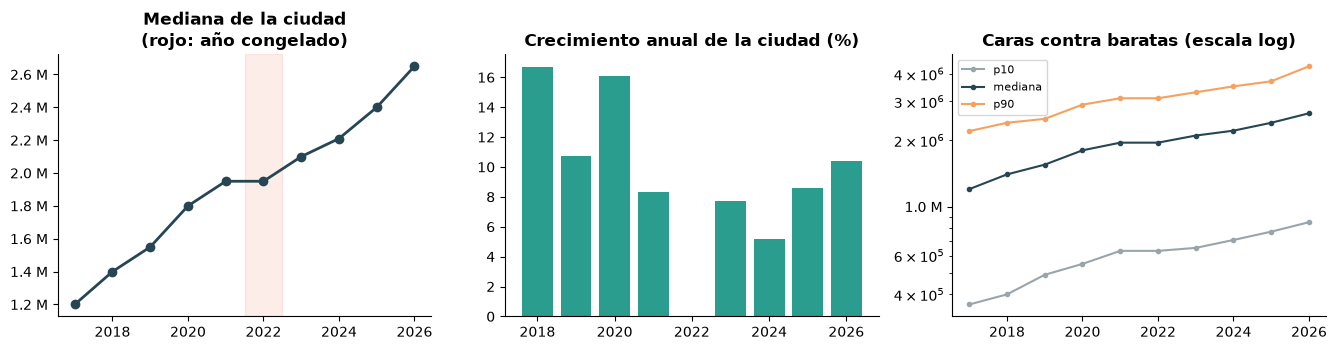

In [3]:
ciudad = completas.median()
deriva_anual = LOG.median().diff()

resumen_anual = pd.DataFrame({
    "mediana_ciudad": ciudad,
    "crecimiento_pct": deriva_anual.map(pct).round(1),
    "pct_sin_cambio": (100 * (completas.diff(axis=1) == 0).mean()).round(1)})
congelados = resumen_anual.index[resumen_anual["pct_sin_cambio"] > 80].tolist()

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))
ax[0].plot(ciudad.index, ciudad.values, "o-", color=AZUL, lw=2)
for a in congelados:
    ax[0].axvspan(a - .5, a + .5, color=ROJO, alpha=.12)
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(pesos))
ax[0].set_title("Mediana de la ciudad\n(rojo: año congelado)", fontweight="bold")

anios = resumen_anual.index[1:]
ax[1].bar(anios, resumen_anual["crecimiento_pct"].iloc[1:],
          color=[ROJO if a in congelados else VERDE for a in anios])
ax[1].set_title("Crecimiento anual de la ciudad (%)", fontweight="bold")

for q, color, nombre in [(.1, GRIS, "p10"), (.5, AZUL, "mediana"), (.9, NARANJA, "p90")]:
    ax[2].plot(completas.columns, completas.quantile(q), "o-", color=color, ms=3, label=nombre)
ax[2].set_yscale("log"); ax[2].yaxis.set_major_formatter(plt.FuncFormatter(pesos))
ax[2].set_title("Caras contra baratas (escala log)", fontweight="bold"); ax[2].legend(fontsize=8)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

razon = completas.quantile(.9) / completas.quantile(.1)
print("años congelados (mas del 80% de manzanas sin cambio):", congelados)
print("razon p90/p10: %.1f en %d -> %.1f en %d" % (razon.iloc[0], C.ANIO_INI, razon.iloc[-1], C.ANIO))
resumen_anual.T.round(1)

40 610 manzanas tienen los diez años completos (93 %). La mediana pasó de 1,2 M a
2,65 M, pero el ritmo se frenó: 16 % anual en 2018 y 2020, entre 5 % y 10 % desde
2023.

**2022 está congelado**: el 100 % de las manzanas tiene el mismo valor que en
2021. No falta el dato; Catastro no actualizó. Se deja en el panel porque el
pronóstico tiene que convivir con esa realidad, y en la Parte A se va a notar.

La brecha entre caras y baratas se cerró un poco —el p90 valía 6,1 veces el p10 en
2017 y 5,1 en 2026—: lo barato subió más rápido. Es la reversión a la media, que
va a reaparecer como la única señal firme de la Parte B.

## 2. El diseño de validación

Partir las manzanas al azar mediría lo que no es: el objetivo es predecir **el
futuro de manzanas conocidas**. La partición es **en el tiempo**:

| | Se ajusta con | Se evalúa con |
|---|---|---|
| Variables | historia hasta **2020** | historia hasta **2023** |
| Objetivo | crecimiento **2020 → 2023** | crecimiento **2023 → 2026** |

Las mismas manzanas en los dos bloques; lo que nunca se cruza es el período. El
precio de 2026 no entra por ninguna vía al ajuste.

**Una regla para las variables**, fijada antes de mirar resultados: con un solo
período de entrenamiento, cada variable extra es una oportunidad de memorizarlo,
así que no entran combinaciones lineales de variables que ya están.

Las variables son las del proyecto anterior: 12 de ubicación, el IVS, la historia
de precio de la manzana y la de sus 8 vecinos. El objetivo es el crecimiento
**relativo a la ciudad**: si no, el modelo aprendería la deriva del período de
entrenamiento, que es justo lo que no se repite.

In [4]:
mz = gpd.read_file(C.TABLA)
VARIABLES = ["lon", "lat", "dist_centro_historico_km", "dist_calle_100_km", "dist_aeropuerto_km",
             "dist_centro_sur_km", "dist_cerros_km", "azimut_sin", "azimut_cos",
             "vecinos_500m", "vecinos_1km", "dist_vecino_8_km", "ivs"]

panel = mz[mz["ivs"].notna()].merge(LOG.reset_index(), on="MANCODIGO").reset_index(drop=True)
xy = np.c_[panel["lon"] * np.cos(np.radians(4.65)), panel["lat"]]
vecinos = NearestNeighbors(n_neighbors=K_VECINOS + 1).fit(xy).kneighbors(xy)[1][:, 1:]

# un bloque por origen: variables observables en t0 y crecimiento t0 -> t0+H.
# El de 2026 no tiene objetivo: es el que se usa para pronosticar.
bloques = {}
for t0 in [ORIGEN_TRAIN, ORIGEN_TEST, C.ANIO]:
    nivel = panel[t0].values
    g1 = (panel[t0] - panel[t0 - 1]).values                 # ultimo año
    g2 = ((panel[t0] - panel[t0 - 2]) / 2).values           # ultimo bienio, anual
    X = panel[VARIABLES].copy()
    X["nivel_rel"] = nivel - np.median(nivel)               # que tan cara frente a la ciudad
    X["g1"], X["g2"] = g1, g2
    X["vec_nivel"] = nivel[vecinos].mean(1) - np.median(nivel)
    X["vec_g1"], X["vec_g2"] = g1[vecinos].mean(1), g2[vecinos].mean(1)
    if t0 + H <= C.ANIO:
        crec = (panel[t0 + H] - panel[t0]).values / H
        bloques[t0] = (X, crec - np.median(crec), np.median(crec))
    else:
        bloques[t0] = (X, None, None)

X_tr, y_tr, deriva_tr = bloques[ORIGEN_TRAIN]
X_te, y_te, deriva_te = bloques[ORIGEN_TEST]
X_hoy = bloques[C.ANIO][0]

print("%d manzanas, %d variables" % X_tr.shape)
print("deriva del periodo de ajuste: %.1f%% anual | del de prueba: %.1f%% anual"
      % (pct(deriva_tr), pct(deriva_te)))

37428 manzanas, 19 variables
deriva del periodo de ajuste: 5.0% anual | del de prueba: 8.1% anual


## 3. Parte A — la deriva de la ciudad

Una sola serie de diez puntos, uno congelado. Se comparan seis métodos, de la
caminata aleatoria a ARIMA. El backtest del proyecto anterior ajustaba con
2017-2023 y probaba en 2024-2026.

,error_medio_pct,sesgo_pct,crec_anual_implicito_pct
metodo,,,
deriva reciente (4a),1.6,1.3,7.9
deriva historica,4.9,4.9,9.8
Holt amortiguado,5.9,-5.9,3.5
"ARIMA(0,1,1)+deriva",6.4,6.4,10.5
tendencia lineal,10.0,10.0,11.5
caminata aleatoria,12.7,-12.7,0.0


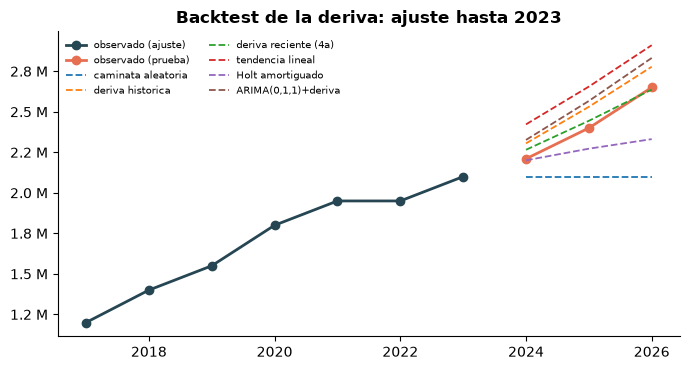

In [5]:
s = np.log10(ciudad)
paso = lambda n: np.arange(1, n + 1)
METODOS = {
    "caminata aleatoria": lambda s, n: np.full(n, s.iloc[-1]),
    "deriva historica": lambda s, n: s.iloc[-1] + (s.iloc[-1] - s.iloc[0]) / (len(s) - 1) * paso(n),
    "deriva reciente (4a)": lambda s, n: s.iloc[-1] + (s.iloc[-1] - s.iloc[-5]) / 4 * paso(n),
    "tendencia lineal": lambda s, n: np.polyval(np.polyfit(np.arange(len(s)), s.values, 1),
                                                np.arange(len(s), len(s) + n)),
    "Holt amortiguado": lambda s, n: ExponentialSmoothing(
        s.values, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(n),
    "ARIMA(0,1,1)+deriva": lambda s, n: ARIMA(s.values, order=(0, 1, 1), trend="t").fit().forecast(n),
}

ent, obj = s.loc[:ORIGEN_TEST], s.loc[ORIGEN_TEST + 1:]
filas, curvas = [], {}
for nombre, f in METODOS.items():
    p = np.asarray(f(ent, len(obj)), dtype=float)
    curvas[nombre] = p
    err = 100 * (10 ** p - 10 ** obj.values) / 10 ** obj.values
    filas.append({"metodo": nombre, "error_medio_pct": np.abs(err).mean(),
                  "sesgo_pct": err.mean(), "crec_anual_implicito_pct": pct(np.diff(np.r_[ent.iloc[-1], p]).mean())})
backtest = pd.DataFrame(filas).set_index("metodo").sort_values("error_medio_pct").round(1)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ent.index, 10 ** ent, "o-", color=AZUL, lw=2, label="observado (ajuste)")
ax.plot(obj.index, 10 ** obj, "o-", color=ROJO, lw=2, label="observado (prueba)")
for nombre, p in curvas.items():
    ax.plot(obj.index, 10 ** p, "--", lw=1.3, label=nombre)
ax.yaxis.set_major_formatter(plt.FuncFormatter(pesos))
ax.set_title("Backtest de la deriva: ajuste hasta %d" % ORIGEN_TEST, fontweight="bold")
ax.legend(fontsize=7, ncol=2, frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

backtest

### ¿El ganador es real o es la ventana?

Un solo backtest de tres años elige ganador sobre tres observaciones. Para ver
si hay sobreajuste en esa elección se repite el ejercicio desde **varios
orígenes** —2021, 2022 y 2023— prediciendo hasta tres años adelante cada vez.
Si el método ganador solo gana desde 2023, se eligió por la ventana y no por el
método.

Los modelos con más parámetros son los candidatos naturales a sobreajustar: Holt
amortiguado estima cinco —tres de suavizado y dos valores iniciales— y ARIMA
tres, con entre cinco y siete puntos de historia.

ganador con una sola ventana (2023) : deriva reciente (4a)
ganador promediando tres origenes   : Holt amortiguado


origen,2021,2022,2023,promedio,peor_origen,puesto_medio
metodo,,,,,,
Holt amortiguado,11.4,2.0,5.9,6.4,11.4,2.0
deriva reciente (4a),19.4,3.1,1.6,8.0,19.4,2.5
deriva historica,19.4,6.1,4.9,10.1,19.4,3.2
"ARIMA(0,1,1)+deriva",21.9,3.0,6.4,10.5,21.9,3.7
caminata aleatoria,6.3,12.6,12.7,10.5,12.7,4.0
tendencia lineal,21.9,14.6,10.0,15.5,21.9,5.7


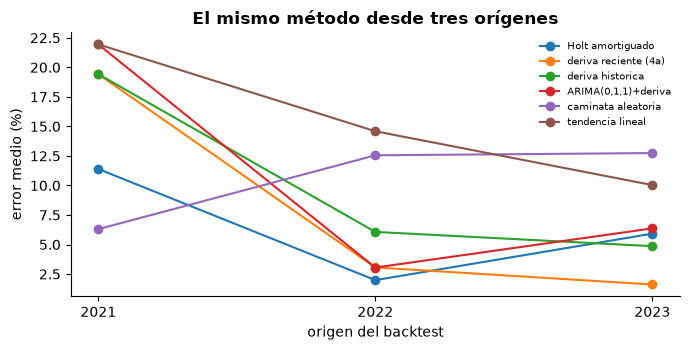

In [6]:
filas = []
for origen in [2021, 2022, 2023]:
    ent = s.loc[:origen]
    obj = s.loc[origen + 1: min(origen + H, C.ANIO)]
    for nombre, f in METODOS.items():
        try:
            p = np.asarray(f(ent, len(obj)), dtype=float)
            filas.append({"origen": origen, "metodo": nombre,
                          "error_pct": 100 * np.mean(np.abs(10 ** p - 10 ** obj.values) / 10 ** obj.values)})
        except Exception as e:                   # con 5 puntos algun ajuste no converge
            filas.append({"origen": origen, "metodo": nombre, "error_pct": np.nan})

movil = pd.DataFrame(filas).pivot(index="metodo", columns="origen", values="error_pct")
movil["promedio"] = movil.mean(axis=1, skipna=False)      # si falla en un origen, no compite
movil["peor_origen"] = movil[[2021, 2022, 2023]].max(axis=1)
puestos = movil[[2021, 2022, 2023]].rank()
movil["puesto_medio"] = puestos.mean(axis=1)
movil = movil.sort_values("promedio")

fig, ax = plt.subplots(figsize=(7, 3.6))
for nombre, fila in movil.iterrows():
    ax.plot([2021, 2022, 2023], fila[[2021, 2022, 2023]], "o-", lw=1.5, label=nombre)
ax.set_xticks([2021, 2022, 2023]); ax.set_xlabel("origen del backtest")
ax.set_ylabel("error medio (%)")
ax.set_title("El mismo método desde tres orígenes", fontweight="bold")
ax.legend(fontsize=7, frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

ganador_ventana = backtest.index[0]
ganador_movil = movil.index[0]
print("ganador con una sola ventana (2023) : %s" % ganador_ventana)
print("ganador promediando tres origenes   : %s" % ganador_movil)
movil.round(1)

**Hay sobreajuste, pero no en el modelo sino en la elección del modelo.**

Con una sola ventana gana la deriva reciente, con 1,6 % de error. Desde otros
orígenes la historia cambia: desde 2021 esa misma deriva se equivoca un 19 %, y
el orden de los métodos se reacomoda en cada origen —desde 2021 gana la caminata
aleatoria, porque el año siguiente fue justo el congelado; desde 2022, Holt;
desde 2023, la deriva reciente—. El ganador del proyecto anterior lo era por la
ventana.

Holt queda primero en promedio (6,4 %), pero tampoco sirve como elección: su
pronóstico para 2027-2030 es 3,9 % anual, menos que cualquier trienio que la
ciudad haya tenido, porque amortigua un freno que en buena parte es el año
congelado.

Lo que sí deja claro el backtest es el tamaño del error: entre 2 % y 22 % según
el método y el origen. Ese es el ancho real de lo que no se sabe sobre la deriva.

### Los escenarios de deriva

Si el backtest no alcanza para elegir un método, el escenario central no debería
salir de un método. Lo defendible es **un rango anclado en lo que la ciudad
hizo**: el trienio más flojo, la **mediana de los trienios** y el más fuerte. Al
lado, lo que habría pronosticado cada método con la serie completa, para ver
dónde caen. Todo nominal.

In [7]:
trienios = pd.Series({a: (s[a + H] - s[a]) / H for a in range(C.ANIO_INI, C.ANIO - H + 1)})
deriva_central = trienios.median()

escenarios = pd.DataFrame({
    "deriva_log10": [trienios.min(), deriva_central, trienios.max()],
    "origen": ["trienio mas flojo (%d-%d)" % (trienios.idxmin(), trienios.idxmin() + H),
               "mediana de los %d trienios" % len(trienios),
               "trienio mas fuerte (%d-%d)" % (trienios.idxmax(), trienios.idxmax() + H)]},
    index=["bajo", "central", "alto"])
escenarios["crecimiento_anual_pct"] = escenarios["deriva_log10"].map(pct).round(1)

segun_metodo = pd.Series({n: pct(np.diff(np.r_[s.iloc[-1], f(s, ANIOS_PRONOSTICO)]).mean())
                          for n, f in METODOS.items()}, name="crec_anual_pct").round(1)
print("lo que pronosticaria cada metodo para %d-%d:" % (C.ANIO + 1, C.ANIO + ANIOS_PRONOSTICO))
print(segun_metodo.sort_values().to_string())
print("\ntrienios observados (%% anual): %s" % ", ".join("%d: %.1f" % (a, pct(v)) for a, v in trienios.items()))
escenarios

lo que pronosticaria cada metodo para 2027-2030:
caminata aleatoria      0.0
Holt amortiguado        3.9
deriva reciente (4a)    8.0
tendencia lineal        8.6
deriva historica        9.2
ARIMA(0,1,1)+deriva     9.5

trienios observados (% anual): 2017: 14.5, 2018: 11.7, 2019: 8.0, 2020: 5.3, 2021: 4.3, 2022: 7.2, 2023: 8.1


,deriva_log10,origen,crecimiento_anual_pct
bajo,0.018119,trienio mas flojo (2021-2024),4.3
central,0.033234,mediana de los 7 trienios,8.0
alto,0.058697,trienio mas fuerte (2017-2020),14.5


## 4. Parte B — qué manzanas le ganan a la ciudad

El objetivo es el término relativo: cuánto crece una manzana por encima o por
debajo de la mediana, en puntos de log10 anuales. Cero es "crece como Bogotá".

Diez métodos, del más tonto al más flexible. Los tres primeros son **líneas
base**: si un Random Forest no le gana a "todas crecen igual", sobra.

In [8]:
escala = lambda m: make_pipeline(StandardScaler(), m)
MODELOS = {
    "linea base (= ciudad)": None,
    "momentum": None,
    "reversion a la media": (LinearRegression(), ["nivel_rel"]),
    "Ridge": (escala(RidgeCV(alphas=np.logspace(-3, 3, 25))), None),
    "ElasticNet": (escala(ElasticNetCV(l1_ratio=[.2, .5, .9], cv=4, random_state=C.SEMILLA)), None),
    "arbol de decision": (DecisionTreeRegressor(max_depth=6, min_samples_leaf=200,
                                                random_state=C.SEMILLA), None),
    "KNN espacial (k=40)": (escala(KNeighborsRegressor(40, weights="distance")), ["lon", "lat"]),
    "Random Forest": (RandomForestRegressor(300, min_samples_leaf=20, n_jobs=-1,
                                            random_state=C.SEMILLA), None),
    "Extra Trees": (ExtraTreesRegressor(300, min_samples_leaf=20, n_jobs=-1,
                                        random_state=C.SEMILLA), None),
    "Gradient Boosting": (HistGradientBoostingRegressor(max_iter=400, learning_rate=.05,
                                                        min_samples_leaf=40,
                                                        random_state=C.SEMILLA), None),
}

pred, ajustados = {}, {}
for nombre, spec in MODELOS.items():
    if nombre == "linea base (= ciudad)":
        pred[nombre] = np.zeros(len(X_te))
    elif nombre == "momentum":                    # su crecimiento reciente relativo continua
        pred[nombre] = X_te["g2"].values - np.median(X_tr["g2"])
    else:
        modelo, cols = spec
        cols = cols or list(X_tr.columns)
        ajustados[nombre] = (modelo.fit(X_tr[cols], y_tr), cols)
        pred[nombre] = modelo.predict(X_te[cols])

# ensamble: promedio de los tres con menor error cuadratico
ecm = {n: np.mean((y_te - p) ** 2) for n, p in pred.items() if n in ajustados}
mejores3 = sorted(ecm, key=ecm.get)[:3]
pred["ensamble (3 mejores)"] = np.mean([pred[n] for n in mejores3], axis=0)
print("ensamble = promedio de:", ", ".join(mejores3))

ensamble = promedio de: arbol de decision, Random Forest, Extra Trees


Cada métrica responde una pregunta distinta, y aquí no coinciden:

| Métrica | Pregunta |
|---|---|
| `r2_relativo` | ¿explica la varianza del crecimiento relativo? |
| `mae_log10` / `rmse_log10` | ¿de cuánto es el error típico / cuánto pesan los errores grandes? |
| `error_precio_pct` | en pesos, ¿cuánto se equivoca el precio a 3 años? |
| `spearman` | ¿ordena bien las manzanas? |
| `acierto_direccion` | ¿acierta si crece más o menos que la ciudad? |
| `lift_decil_top` | si compro el 10 % que señala, ¿cuánto más crece que la ciudad? |

In [9]:
precio_ini = panel[ORIGEN_TEST].values
filas = []
for nombre, p in pred.items():
    real = precio_ini + (y_te + deriva_te) * H            # precio a 3 años, real y estimado
    est = precio_ini + (p + deriva_te) * H
    decil = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False).values
    filas.append({
        "modelo": nombre,
        "r2_relativo": 1 - np.sum((y_te - p) ** 2) / np.sum((y_te - y_te.mean()) ** 2),
        "mae_log10": np.mean(np.abs(y_te - p)),
        "rmse_log10": np.sqrt(np.mean((y_te - p) ** 2)),
        "error_precio_pct": 100 * np.median(np.abs(10 ** est - 10 ** real) / 10 ** real),
        "spearman": pd.Series(p).corr(pd.Series(y_te), method="spearman"),
        "acierto_direccion": 100 * np.mean((p > 0) == (y_te > 0)),
        "lift_decil_top": pct(y_te[decil == 9].mean() + deriva_te) - pct(y_te.mean() + deriva_te)})

tabla_b = pd.DataFrame(filas).set_index("modelo").sort_values("r2_relativo", ascending=False)
for m in ["r2_relativo", "mae_log10", "spearman", "lift_decil_top"]:
    asc = m == "mae_log10"
    print("mejor por %-15s: %s" % (m, tabla_b[m].sort_values(ascending=asc).index[0]))
tabla_b.round(4)

mejor por r2_relativo    : ensamble (3 mejores)
mejor por mae_log10      : reversion a la media
mejor por spearman       : reversion a la media
mejor por lift_decil_top : reversion a la media


,r2_relativo,mae_log10,rmse_log10,error_precio_pct,spearman,acierto_direccion,lift_decil_top
modelo,,,,,,,
ensamble (3 mejores),0.1345,0.0185,0.0329,8.1345,0.1819,57.1043,1.1812
arbol de decision,0.1155,0.0184,0.0332,7.7871,0.1748,55.9875,6.0342
Random Forest,0.0932,0.0191,0.0337,8.4528,0.1672,55.5600,1.0904
Extra Trees,0.0860,0.0191,0.0338,8.3931,0.1407,56.2573,0.5538
Gradient Boosting,0.0635,0.0194,0.0342,8.5268,0.1444,54.6463,2.5449
ElasticNet,0.0586,0.0197,0.0343,9.3079,0.3028,56.4177,6.2710
reversion a la media,0.0568,0.0183,0.0343,7.6425,0.3175,60.2811,7.0768
Ridge,0.0157,0.0202,0.0351,9.3539,0.2779,56.3722,5.8820
linea base (= ciudad),-0.0029,0.0187,0.0354,7.8023,NaN,50.0053,2.9520


El ensamble gana en R² (0,135) y la **reversión a la media gana todo lo demás**:
menor error, mejor ordenamiento (Spearman 0,32), mejor lift —el 10 % que señala
creció 7,1 puntos por encima de la ciudad— y mejor acierto de dirección (60 %).
Momentum y KNN espacial son los peores, y por mucho: lo que subió no sigue
subiendo, y el crecimiento de los vecinos no se contagia.

Los árboles explican más varianza pero ordenan peor: aciertan unas pocas
manzanas con saltos grandes, que pesan mucho en el R², y no la tendencia general,
que es simplemente que lo barato sube más.

## 5. Qué dicen las métricas

### 5.1 El R² sobre el precio es una trampa

Evaluado sobre el **precio** y no sobre el crecimiento, todo modelo parece
excelente —hasta el que dice que nada cambia—, porque el precio de dentro de tres
años ya se parece muchísimo al de hoy.

In [10]:
real_fin = panel[ORIGEN_TEST + H].values
r2 = lambda real, est: 1 - np.sum((real - est) ** 2) / np.sum((real - real.mean()) ** 2)
ganador_r2 = tabla_b.index[0]

filas = [{"modelo": n,
          "R2 sobre el precio": r2(real_fin, precio_ini + (pred[n] + deriva_te) * H),
          "R2 sobre el crecimiento relativo": tabla_b.loc[n, "r2_relativo"]}
         for n in dict.fromkeys(["linea base (= ciudad)", "reversion a la media", ganador_r2])]
filas.append({"modelo": "el precio se queda quieto", "R2 sobre el precio": r2(real_fin, precio_ini),
              "R2 sobre el crecimiento relativo": np.nan})
pd.DataFrame(filas).set_index("modelo").round(3)

,R2 sobre el precio,R2 sobre el crecimiento relativo
modelo,,
linea base (= ciudad),0.843,-0.003
reversion a la media,0.853,0.057
ensamble (3 mejores),0.865,0.135
el precio se queda quieto,0.684,NaN


Por eso **todas las métricas de este notebook van sobre el crecimiento
relativo**.

### 5.2 La métrica depende de la decisión

Un modelo de valorización sirve para dos cosas distintas:

- **Tasar** —poner un número en un flujo de caja— pide error bajo:
  `error_precio_pct`, `mae_log10`.
- **Elegir dónde comprar** pide **ordenar** bien: `spearman`, `lift_decil_top`.
  Ahí no importa si el nivel está corrido, siempre que el orden sea correcto.

La curva de deciles muestra lo segundo: se agrupan las manzanas por lo que el
modelo predijo y se mira lo que de verdad crecieron. La calibración dice si el
modelo exagera las diferencias; esa pendiente se usa después para encoger el
pronóstico.

pendiente de calibracion: 0.19 -> cuando el modelo anuncia 10 puntos de diferencia, la realidad entrega 1.9


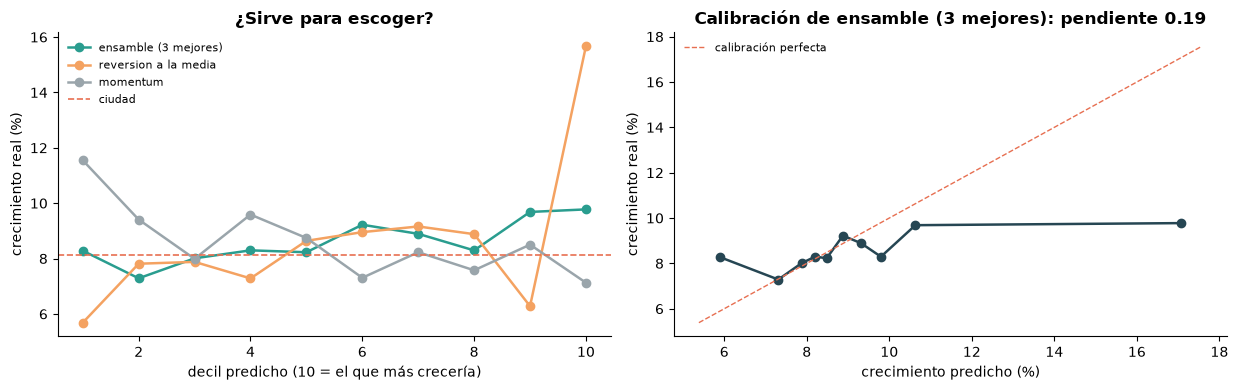

In [11]:
mejor_orden = tabla_b["spearman"].idxmax()

curvas = {ganador_r2: VERDE}
curvas.setdefault(mejor_orden, NARANJA)
curvas["momentum"] = GRIS

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
for nombre, color in curvas.items():
    dec = pd.qcut(pd.Series(pred[nombre]).rank(method="first"), 10, labels=False)
    ax[0].plot(range(1, 11), pd.Series(y_te).groupby(dec).mean().map(lambda v: pct(v + deriva_te)),
               "o-", color=color, lw=1.8, label=nombre)
ax[0].axhline(pct(deriva_te), color=ROJO, ls="--", lw=1.2, label="ciudad")
ax[0].set_xlabel("decil predicho (10 = el que más crecería)"); ax[0].set_ylabel("crecimiento real (%)")
ax[0].set_title("¿Sirve para escoger?", fontweight="bold"); ax[0].legend(fontsize=8, frameon=False)

dec = pd.qcut(pd.Series(pred[ganador_r2]).rank(method="first"), 10, labels=False)
x_dec = pd.Series(pred[ganador_r2]).groupby(dec).mean().map(lambda v: pct(v + deriva_te))
y_dec = pd.Series(y_te).groupby(dec).mean().map(lambda v: pct(v + deriva_te))
pendiente = float(np.polyfit(x_dec, y_dec, 1)[0])
ax[1].plot(x_dec, y_dec, "o-", color=AZUL, lw=1.8)
lims = [min(x_dec.min(), y_dec.min()) - .5, max(x_dec.max(), y_dec.max()) + .5]
ax[1].plot(lims, lims, "--", color=ROJO, lw=1, label="calibración perfecta")
ax[1].set_xlabel("crecimiento predicho (%)"); ax[1].set_ylabel("crecimiento real (%)")
ax[1].set_title("Calibración de %s: pendiente %.2f" % (ganador_r2, pendiente), fontweight="bold")
ax[1].legend(fontsize=8, frameon=False)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

print("pendiente de calibracion: %.2f -> cuando el modelo anuncia 10 puntos de diferencia, "
      "la realidad entrega %.1f" % (pendiente, 10 * pendiente))

### 5.3 ¿La diferencia entre modelos es real o es ruido?

El crecimiento es un fenómeno de zona: dos manzanas del mismo sector aportan casi
la misma información. Un intervalo calculado manzana a manzana saldría falsamente
angosto. Se remuestrean **sectores completos** y se mide la mejora del MAE frente
a la línea base.

modelos que le ganan a la linea base con 95% de confianza: 0 de 10


,mejora_mae,ic95_bajo,ic95_alto,le_gana_a_la_base
modelo,,,,
reversion a la media,0.00029,-0.00033,0.00095,False
arbol de decision,0.00026,-0.00043,0.00103,False
ensamble (3 mejores),0.00014,-0.00065,0.00102,False
Random Forest,-0.00042,-0.00116,0.00037,False
Extra Trees,-0.00047,-0.00107,0.00016,False
Gradient Boosting,-0.00076,-0.00146,0.00014,False
ElasticNet,-0.00105,-0.00166,-0.00035,False
Ridge,-0.00154,-0.00217,-0.00096,False
KNN espacial (k=40),-0.00916,-0.01041,-0.00796,False


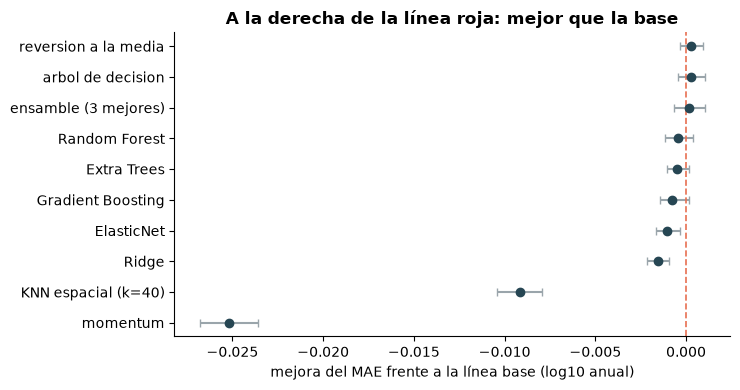

In [12]:
sector = panel["sector"].values
filas_sector = {s: np.where(sector == s)[0] for s in np.unique(sector)}
claves = np.array(list(filas_sector))
base = pred["linea base (= ciudad)"]

filas = []
for nombre, p in pred.items():
    if nombre == "linea base (= ciudad)":
        continue
    mejora = []
    for _ in range(N_BOOT):
        i = np.concatenate([filas_sector[k] for k in rng.choice(claves, len(claves))])
        mejora.append(np.abs(y_te[i] - base[i]).mean() - np.abs(y_te[i] - p[i]).mean())
    filas.append({"modelo": nombre, "mejora_mae": np.mean(mejora),
                  "ic95_bajo": np.percentile(mejora, 2.5), "ic95_alto": np.percentile(mejora, 97.5)})
boot = pd.DataFrame(filas).set_index("modelo").sort_values("mejora_mae")
boot["le_gana_a_la_base"] = boot["ic95_bajo"] > 0

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.errorbar(boot["mejora_mae"], range(len(boot)),
            xerr=[boot["mejora_mae"] - boot["ic95_bajo"], boot["ic95_alto"] - boot["mejora_mae"]],
            fmt="o", color=AZUL, ecolor=GRIS, capsize=3)
ax.axvline(0, color=ROJO, ls="--", lw=1.2)
ax.set_yticks(range(len(boot)), boot.index)
ax.set_xlabel("mejora del MAE frente a la línea base (log10 anual)")
ax.set_title("A la derecha de la línea roja: mejor que la base", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

print("modelos que le ganan a la linea base con 95%% de confianza: %d de %d"
      % (boot["le_gana_a_la_base"].sum(), len(boot)))
boot.iloc[::-1].round(5)

**Ninguno de los diez le gana a la línea base con 95 % de confianza.** La
reversión a la media es la que más se acerca: mejora el error en 0,0003 log por
año, con un intervalo de −0,0003 a +0,0010 que todavía cruza el cero. Ridge,
ElasticNet, KNN y momentum son peores que la base con certeza.

Y la calibración del ensamble es de 0,19: cuando anuncia 10 puntos de diferencia
entre dos manzanas, la realidad entrega 1,9. Exagera cinco veces.

Dicho sin rodeos: con estas variables, predecir qué manzana le gana a la ciudad
es casi tan difícil como no intentarlo.

### 5.4 De dónde sale la señal

Importancia por permutación sobre el Gradient Boosting: cuánto empeora el error
al desordenar cada variable.

nivel_rel                   0.01971
vec_nivel                   0.00281
dist_calle_100_km           0.00118
g2                          0.00118
azimut_sin                  0.00033
dist_vecino_8_km            0.00029
dist_centro_historico_km    0.00028
lon                         0.00019
dtype: float64

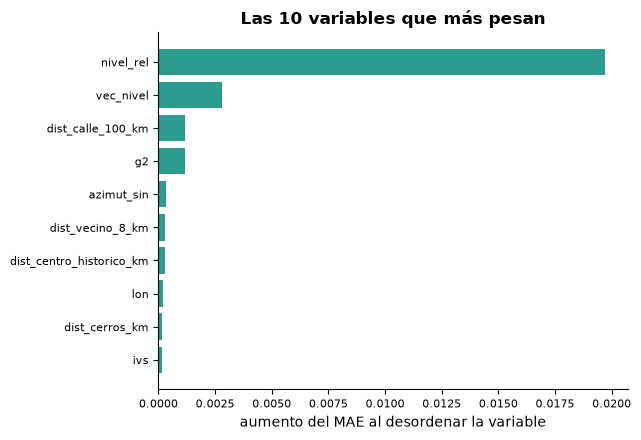

In [13]:
modelo, cols = ajustados["Gradient Boosting"]
muestra = rng.choice(len(X_te), min(8000, len(X_te)), replace=False)
imp = permutation_importance(modelo, X_te[cols].iloc[muestra], y_te[muestra], n_repeats=5,
                             random_state=C.SEMILLA, scoring="neg_mean_absolute_error")
importancia = pd.Series(imp.importances_mean, index=cols).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(importancia.index[-10:], importancia.values[-10:], color=VERDE)
ax.set_xlabel("aumento del MAE al desordenar la variable")
ax.set_title("Las 10 variables que más pesan", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.tick_params(labelsize=8)
fig.tight_layout()

importancia.iloc[::-1].head(8).round(5)

### 5.5 Qué modelo usar para qué

In [14]:
pd.DataFrame([
    {"pregunta": "¿cuánto valdrá esta manzana?", "metrica": "mae_log10",
     "modelo": tabla_b["mae_log10"].idxmin(),
     "valor": "%.1f %% de error en el precio" % tabla_b.loc[tabla_b["mae_log10"].idxmin(), "error_precio_pct"]},
    {"pregunta": "¿dónde conviene comprar?", "metrica": "spearman",
     "modelo": mejor_orden, "valor": "rho %.3f" % tabla_b.loc[mejor_orden, "spearman"]},
    {"pregunta": "¿cuánto gana el 10 % mejor señalado?", "metrica": "lift_decil_top",
     "modelo": tabla_b["lift_decil_top"].idxmax(),
     "valor": "+%.1f puntos anuales" % tabla_b["lift_decil_top"].max()},
    {"pregunta": "¿crecerá más o menos que la ciudad?", "metrica": "acierto_direccion",
     "modelo": tabla_b["acierto_direccion"].idxmax(),
     "valor": "%.1f %%" % tabla_b["acierto_direccion"].max()},
]).set_index("pregunta")

,metrica,modelo,valor
pregunta,,,
¿cuánto valdrá esta manzana?,mae_log10,reversion a la media,7.6 % de error en el precio
¿dónde conviene comprar?,spearman,reversion a la media,rho 0.318
¿cuánto gana el 10 % mejor señalado?,lift_decil_top,reversion a la media,+7.1 puntos anuales
¿crecerá más o menos que la ciudad?,acierto_direccion,reversion a la media,60.3 %


La reversión a la media gana las cuatro preguntas, y es la conclusión más útil de
esta parte: una recta sobre el precio relativo hace todo lo que hacen los demás,
y mejor. La señal es una sola —lo barato crece más rápido en porcentaje— y la
importancia por permutación lo confirma: el nivel de precio pesa 0,0197, siete
veces más que lo siguiente (el nivel de los vecinos). La ubicación casi no
aporta; la distancia al centro histórico aparece séptima con 0,0003.

## 6. Parte C — el pronóstico

Para cada manzana:

```
precio(2030) = precio(2026) × (1 + deriva)^4 × (1 + relativo)^4
```

La deriva sale de la Parte A (tres escenarios). El término relativo, del modelo
con menor RMSE en la Parte B —el criterio se fija antes: el pronóstico entrega un
valor esperado, y el error cuadrático es el que apunta a la media—, reajustado
con los dos orígenes juntos y aplicado a la foto de 2026.

Dos frenos, ambos medidos arriba: el relativo se **encoge** por la pendiente de
calibración, y se **topa** en el percentil 99 de lo observado.

In [15]:
nombre_final = tabla_b["rmse_log10"].idxmin()
if nombre_final not in ajustados and not nombre_final.startswith("ensamble"):
    nombre_final = "reversion a la media"      # una linea base no se puede reajustar
componentes = mejores3 if nombre_final.startswith("ensamble") else [nombre_final]

y_todo = np.r_[y_tr, y_te]
rel = np.mean([clone(ajustados[n][0]).fit(pd.concat([X_tr[ajustados[n][1]], X_te[ajustados[n][1]]]),
                                          y_todo).predict(X_hoy[ajustados[n][1]])
               for n in componentes], axis=0)

rel = rel - np.median(rel)                   # relativo a la ciudad: 0 en la manzana mediana
factor = min(max(pendiente, 0), 1)
tope = np.percentile(np.abs(y_te), 99)
rel = np.clip(rel * factor, -tope, tope)

nivel_hoy = panel[C.ANIO].values
fin = C.ANIO + ANIOS_PRONOSTICO
pron = panel[["MANCODIGO", "sector", "geometry"]].copy()
pron["cop_m2_%d" % C.ANIO] = 10 ** nivel_hoy
pron["crec_relativo_pct"] = pct(rel).round(2)
for esc, deriva in escenarios["deriva_log10"].items():
    pron["cop_m2_%d_%s" % (fin, esc)] = (10 ** (nivel_hoy + (deriva + rel) * ANIOS_PRONOSTICO)).round(0)
pron["crec_anual_pct"] = pct(deriva_central + rel).round(2)
pron["ganancia_cop_m2"] = pron["cop_m2_%d_central" % fin] - pron["cop_m2_%d" % C.ANIO]

pron.drop(columns="geometry").to_csv(C.PROC / "pronostico_manzanas.csv.gz", index=False)

print("modelo: %s%s" % (nombre_final, "  (%s)" % ", ".join(componentes) if len(componentes) > 1 else ""))
print("encogimiento x%.2f | tope +-%.1f puntos anuales" % (factor, pct(tope)))
print("el termino relativo mueve al 90%% de las manzanas entre %+.2f y %+.2f puntos anuales"
      % tuple(np.percentile(pron["crec_relativo_pct"], [5, 95])))
print("mediana de la ciudad: %s (%d) -> %s (%d, central) | rango %s a %s"
      % (pesos(pron["cop_m2_%d" % C.ANIO].median()), C.ANIO,
         pesos(pron["cop_m2_%d_central" % fin].median()), fin,
         pesos(pron["cop_m2_%d_bajo" % fin].median()), pesos(pron["cop_m2_%d_alto" % fin].median())))

modelo: ensamble (3 mejores)  (arbol de decision, Random Forest, Extra Trees)
encogimiento x0.19 | tope +-44.2 puntos anuales
el termino relativo mueve al 90% de las manzanas entre -0.40 y +0.75 puntos anuales
mediana de la ciudad: 2.8 M (2026) -> 3.8 M (2030, central) | rango 3.3 M a 4.8 M


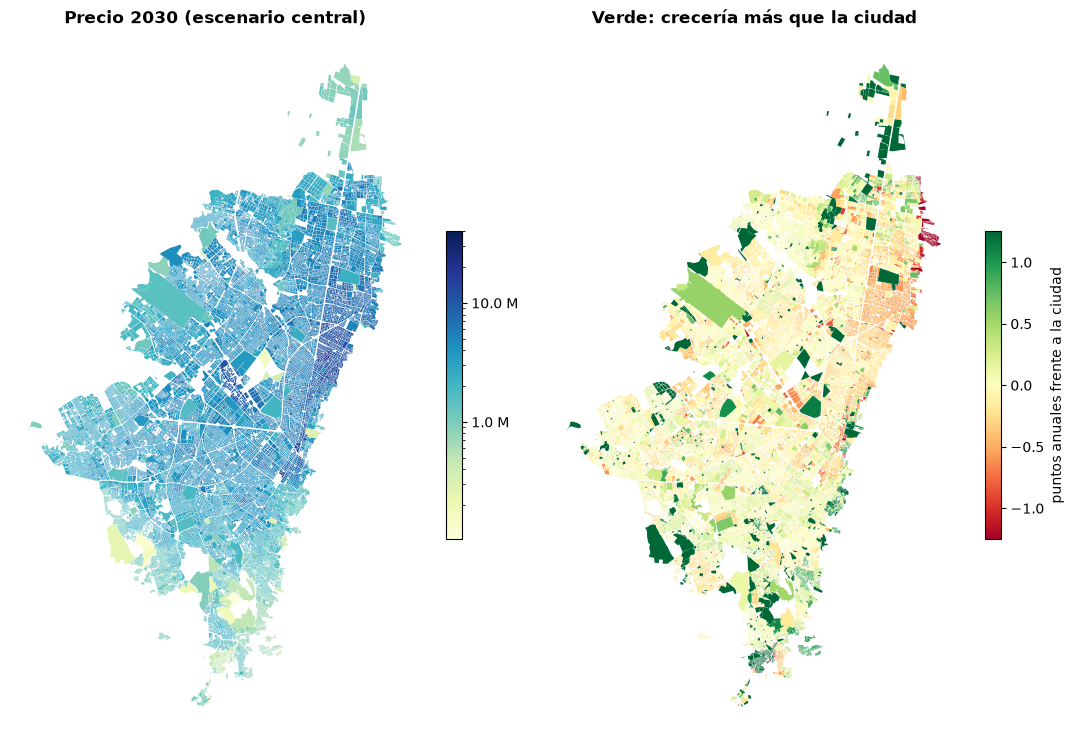

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(2 * TAM_MAPA[0] + 1, TAM_MAPA[1]))
pron.plot(column="cop_m2_%d_central" % fin, cmap="YlGnBu", linewidth=0, ax=ax[0], legend=True,
          norm=plt.matplotlib.colors.LogNorm(), legend_kwds={"shrink": .4, "format": plt.FuncFormatter(pesos)})
ax[0].set_title("Precio %d (escenario central)" % fin, fontweight="bold")

lim = np.nanpercentile(np.abs(pron["crec_relativo_pct"]), 97)
pron.plot(column="crec_relativo_pct", cmap="RdYlGn", vmin=-lim, vmax=lim, linewidth=0, ax=ax[1],
          legend=True, legend_kwds={"shrink": .4, "label": "puntos anuales frente a la ciudad"})
ax[1].set_title("Verde: crecería más que la ciudad", fontweight="bold")
for a in ax:
    a.set_axis_off()
fig.tight_layout();

manzanas precio_hoy  crec_anual_pct ganancia
                        sector                                              
mayor crecimiento %     002611        43      295 k          12.620    180 k
                        002542        16      295 k          12.615    180 k
                        002543        47      295 k          12.580    179 k
                        002614        20      295 k          11.775    166 k
                        002538        68      295 k          11.770    166 k
                        002576        48      295 k          11.770    165 k
mayor ganancia en pesos 008310        20     14.3 M           7.605    4.8 M
                        008313        21      8.5 M           7.810    3.0 M
                        008312        18      8.3 M           7.895    3.0 M
                        008307        50      8.7 M           7.620    2.9 M
                        008306        24      8.3 M           7.850    2.9 M
                        008303        30      8.5 M           7.730    2.9 M

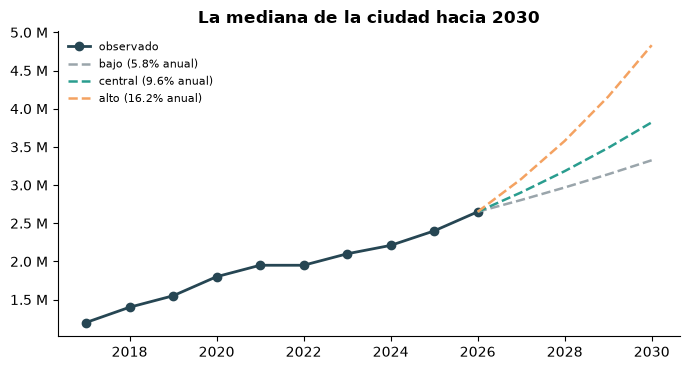

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ciudad.index, ciudad.values, "o-", color=AZUL, lw=2, label="observado")
futuro = range(C.ANIO, fin + 1)
for esc, color in zip(["bajo", "central", "alto"], [GRIS, VERDE, NARANJA]):
    tasa = (pron["cop_m2_%d_%s" % (fin, esc)].median() / ciudad[C.ANIO]) ** (1 / ANIOS_PRONOSTICO)
    ax.plot(futuro, [ciudad[C.ANIO] * tasa ** i for i in range(len(futuro))], "--", color=color,
            lw=1.8, label="%s (%.1f%% anual)" % (esc, 100 * (tasa - 1)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(pesos))
ax.set_title("La mediana de la ciudad hacia %d" % fin, fontweight="bold")
ax.legend(fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

por_sector = (pron.groupby("sector")
              .agg(manzanas=("MANCODIGO", "size"), precio_hoy=("cop_m2_%d" % C.ANIO, "median"),
                   crec_anual_pct=("crec_anual_pct", "median"), ganancia=("ganancia_cop_m2", "median"))
              .query("manzanas >= 15"))
pd.concat({"mayor crecimiento %": por_sector.nlargest(6, "crec_anual_pct"),
           "mayor ganancia en pesos": por_sector.nlargest(6, "ganancia")}).assign(
    precio_hoy=lambda t: t["precio_hoy"].map(pesos), ganancia=lambda t: t["ganancia"].map(pesos))

### Lo que este pronóstico no es

In [18]:
err_modelo = pct(np.median(np.abs(y_te - pred[ganador_r2])))
rango_escenarios = escenarios.loc["alto", "crecimiento_anual_pct"] - escenarios.loc["bajo", "crecimiento_anual_pct"]
pd.Series({
    "1. la deriva de la ciudad (rango entre escenarios)": "%.1f puntos anuales" % rango_escenarios,
    "2. el error del modelo relativo (mediana)": "%.1f puntos anuales" % err_modelo,
    "3. el ruido administrativo": "en %s el %.0f %% de las manzanas no se movio"
        % (congelados[0], resumen_anual.loc[congelados[0], "pct_sin_cambio"]) if congelados else "-",
}, name="fuente de incertidumbre")

1. la deriva de la ciudad (rango entre escenarios)                             10.2 puntos anuales
2. el error del modelo relativo (mediana)                                       2.7 puntos anuales
3. el ruido administrativo                            en 2022 el 100 % de las manzanas no se movio
Name: fuente de incertidumbre, dtype: str

## 7. Lo que queda

- **La deriva de la ciudad es lo que más pesa y lo que menos se puede elegir con
  estos datos.** El backtest móvil mostró que el ganador del proyecto anterior lo
  era por la ventana de prueba. El escenario central ya no sale de un método sino
  de la mediana de lo que la ciudad hizo en cada trienio: **8,0 % anual**, con un
  rango de 4,3 % a 14,5 %. La mediana de la ciudad iría de 2,8 M a 3,8 M en 2030
  (entre 3,3 M y 4,8 M).
- **El término relativo es débil.** Ninguno de diez modelos le gana a "todas
  crecen igual" con 95 % de confianza. Lo único que asoma es la reversión a la
  media.
- **Sirve para ordenar, no para tasar.** El decil que señala la reversión a la
  media creció 7,1 puntos más que la ciudad; el error en pesos a tres años sigue
  en 7,6 %.
- **En el pronóstico final el término relativo casi no mueve nada.** Después de
  encogerlo por la calibración, el 90 % de las manzanas queda entre −0,4 y +0,75
  puntos anuales de la ciudad. En la práctica, el pronóstico de cada manzana es su
  precio de hoy creciendo a la deriva de la ciudad.
- **La incertidumbre grande no es el modelo** (2,7 puntos de error mediano) sino
  el escenario de la ciudad (10,2 puntos entre el bajo y el alto). Un pronóstico
  por manzana con decimales sería un espejismo.

`V_REF` es un valor administrativo: las actualizaciones por turnos y el año
congelado hacen que el modelo aprenda en parte el calendario de Catastro. Cuando
salga el dato de 2027, lo primero es volver a correr el backtest móvil.